Carga de datos

In [1]:
from protocolo.datos import load_train, load_test, split_by_user, num_items

dataset = "netflix"
n_items = num_items(dataset)
train_all = load_train(dataset)          # list[User]
train, val = split_by_user(train_all)    # 90 % / 10 % de los usuarios, por grupo
test = load_test(dataset)

u = train[0]
print(u.user_id, u.group, len(u.items), u.items[:5], u.ratings[:5])

0 0 77 [472  97 122 654 709] [4. 3. 4. 3. 5.]


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

## 1.1 Qué contienen los datos

- **Train** (`train/netflix8_train.df`): 16.000 usuarios (2.000 por grupo). Cada uno tiene entre 25 y 200 ítems valorados, sin repeticiones, **en el orden registrado**. `items[k]` y `ratings[k]` están alineados.
- **Test** (`test_users/netflix8_test.json`): 1.600 usuarios **nuevos** (200 por grupo), con una valoración para **cada** ítem del catálogo. El orden `0, 1, …, 751` es el del catálogo, no un orden de consumo: no se puede evaluar "predecir el siguiente ID".
- **Grupos** (`groups/mu_*.csv`, `sigma_*.csv`): parámetros del generador sintético. Sirven para analizar, **no** para construir políticas.

Como los usuarios de test no aparecen en train, un modelo tiene que generalizar a partir del grupo (si es visible) o de las valoraciones que observa durante la sesión.

El problema se formula como un MDP: **estado** = grupo (si es visible) + ítems mostrados + ratings revelados + paso `t`; **acción** = ítem todavía no mostrado; **recompensa** = rating revelado; **horizonte** = 20 pasos, el último terminal; **γ** a elegir (el retorno evaluado es la suma sin descontar).

In [3]:
from config_dataset import get_paths

paths = get_paths()

usuarios_por_grupo = pd.DataFrame({
    "train": pd.Series([u.group for u in train]).value_counts().sort_index(),
    "val":   pd.Series([u.group for u in val]).value_counts().sort_index(),
    "test":  pd.Series([u.group for u in test]).value_counts().sort_index(),
}).fillna(0).astype(int)
usuarios_por_grupo.index.name = "grupo"
usuarios_por_grupo["total"] = usuarios_por_grupo.sum(axis=1)

print(f"dataset: {dataset} | catálogo: {n_items} ítems")
print(f"usuarios: train={len(train)} + val={len(val)} = {len(train_all)} | test={len(test)}")
print("train y val no comparten usuarios:", {u.user_id for u in train}.isdisjoint({u.user_id for u in val}))
usuarios_por_grupo

dataset: netflix | catálogo: 752 ítems
usuarios: train=14400 + val=1600 = 16000 | test=1600
train y val no comparten usuarios: True


,train,val,test,total
grupo,,,,
0,1800,200,200,2200
1,1800,200,200,2200
2,1800,200,200,2200
3,1800,200,200,2200
4,1800,200,200,2200
5,1800,200,200,2200
6,1800,200,200,2200
7,1800,200,200,2200


### Cantidad de ítems por usuario y escala de los ratings

Cada usuario valoró entre 25 y 200 ítems. En train los ratings son enteros de 1 a 5. En Netflix el test también es entero; en Goodreads el test es continuo (diferencia a reportar si se comparan datasets).

,count,mean,std,min,25%,50%,75%,max
n_items,14400.0,112.22,50.66,25.0,69.0,112.0,156.0,200.0


,mean,std,min,median,max
grupo,,,,,
0,110.9,50.1,25,109.0,200
1,112.9,50.1,25,112.0,200
2,112.0,50.8,25,114.0,200
3,112.5,50.6,25,112.0,200
4,111.8,50.9,25,111.0,200
5,113.8,51.4,25,114.0,200
6,110.9,50.9,25,111.5,200
7,113.0,50.5,25,112.0,200


usuarios con ítems repetidos: 0
ratings train: valores únicos [1. 2. 3. 4. 5.] | min 1, max 5
ratings test: enteros=True | min 1.00, max 5.00


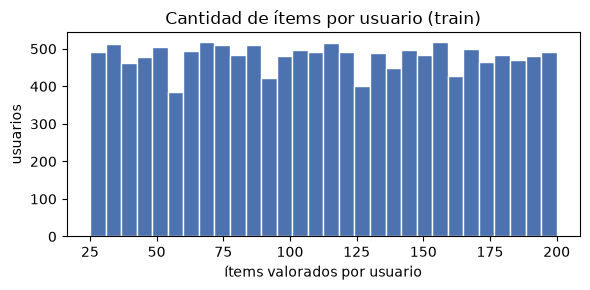

In [4]:
items_por_usuario = pd.DataFrame({
    "grupo": [u.group for u in train],
    "n_items": [len(u.items) for u in train],
})

display(items_por_usuario["n_items"].describe().round(2).to_frame().T)
display(items_por_usuario.groupby("grupo")["n_items"].agg(["mean", "std", "min", "median", "max"]).round(1))

repetidos = sum(len(set(u.items)) != len(u.items) for u in train)
ratings_train = np.concatenate([u.ratings for u in train])
ratings_test = np.concatenate([u.ratings for u in test])
print(f"usuarios con ítems repetidos: {repetidos}")
print(f"ratings train: valores únicos {np.unique(ratings_train)} | min {ratings_train.min():.0f}, max {ratings_train.max():.0f}")
print(f"ratings test: enteros={np.all(ratings_test == np.round(ratings_test))} | min {ratings_test.min():.2f}, max {ratings_test.max():.2f}")

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(items_por_usuario["n_items"], bins=30, color="#4c72b0", edgecolor="white")
ax.set_xlabel("ítems valorados por usuario")
ax.set_ylabel("usuarios")
ax.set_title("Cantidad de ítems por usuario (train)")
plt.tight_layout()
plt.show()

## 1.4 Exploración

En RL offline, **la política que generó los logs determina qué se puede aprender de ellos**. Acá los logs vienen de una política uniforme al azar, así que hay que verificar dos cosas: si el rating medio cambia con la posición en la trayectoria y si los ítems que más aparecen son los mejor valorados.

Se arma una tabla larga con una fila por interacción:

In [5]:
rows = [
    (u.group, pos, item, r)
    for u in train
    for pos, (item, r) in enumerate(zip(u.items, u.ratings))
]
df = pd.DataFrame(rows, columns=["group", "pos", "item", "rating"])
print(f"interacciones en train: {len(df):,}")
df.head()

interacciones en train: 1,615,959


,group,pos,item,rating
0,0,0,472,4.0
1,0,1,97,3.0
2,0,2,122,4.0
3,0,3,654,3.0
4,0,4,709,5.0


### Distribución de ratings

Global y por grupo. Si los grupos tienen gustos distintos, las distribuciones por grupo se desplazan y el rating medio por grupo ya es una señal útil (lo explota `group_mean`).

,proporción
rating,
1.0,0.1390
2.0,0.1797
3.0,0.2219
4.0,0.2461
5.0,0.2134


rating,1.0,2.0,3.0,4.0,5.0
grupo 0,0.050,0.103,0.198,0.320,0.328
grupo 1,0.103,0.152,0.229,0.288,0.229
grupo 2,0.113,0.205,0.279,0.255,0.148
grupo 3,0.191,0.227,0.254,0.211,0.117
grupo 4,0.021,0.055,0.141,0.316,0.468
grupo 5,0.152,0.220,0.253,0.220,0.156
grupo 6,0.103,0.166,0.239,0.273,0.219
grupo 7,0.376,0.307,0.183,0.089,0.046


,mean,std,count
group,,,
0,3.775,1.156,199661
1,3.387,1.271,203160
2,3.119,1.221,201552
3,2.837,1.282,202536
4,4.156,0.994,201156
5,3.008,1.293,204881
6,3.340,1.270,199666
7,2.123,1.145,203347


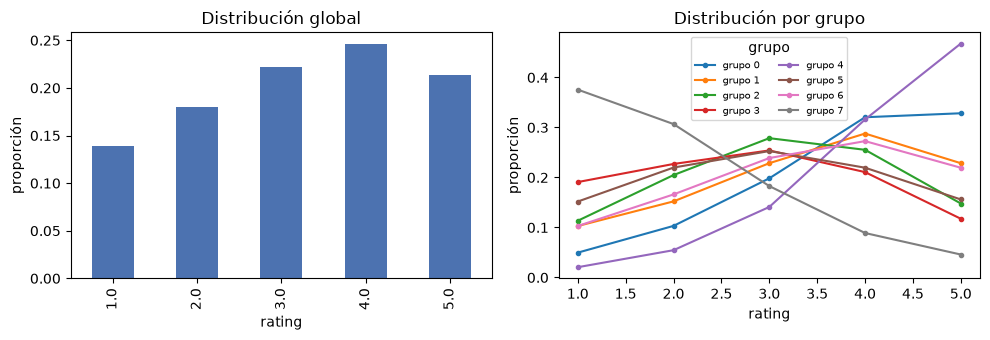

In [6]:
dist_global = df["rating"].value_counts(normalize=True).sort_index().rename("proporción").to_frame()
display(dist_global.round(4))

dist_grupo = (
    df.groupby(["group", "rating"]).size().unstack(fill_value=0)
      .pipe(lambda t: t.div(t.sum(axis=1), axis=0))
)
dist_grupo.index = [f"grupo {g}" for g in dist_grupo.index]
display(dist_grupo.round(3))

display(df.groupby("group")["rating"].agg(["mean", "std", "count"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
df["rating"].value_counts(normalize=True).sort_index().plot.bar(ax=axes[0], color="#4c72b0")
axes[0].set_title("Distribución global")
axes[0].set_xlabel("rating")
axes[0].set_ylabel("proporción")
dist_grupo.T.plot(ax=axes[1], marker="o", ms=3)
axes[1].set_title("Distribución por grupo")
axes[1].set_xlabel("rating")
axes[1].set_ylabel("proporción")
axes[1].legend(fontsize=7, ncol=2, title="grupo")
plt.tight_layout()
plt.show()

### ¿El rating medio cambia con la posición en la trayectoria?

Con una política de registro uniforme no debería haber relación. Se compara el rating medio por bloques de posición y se calcula la correlación de Spearman entre posición y rating.

,count,mean,std
bloque,,,
"[0, 10)",144000,3.226,1.338
"[10, 25)",216000,3.215,1.338
"[25, 50)",333339,3.216,1.337
"[50, 100)",513106,3.217,1.338
"[100, 200)",409514,3.209,1.337


Spearman(posición, rating) = -0.0028


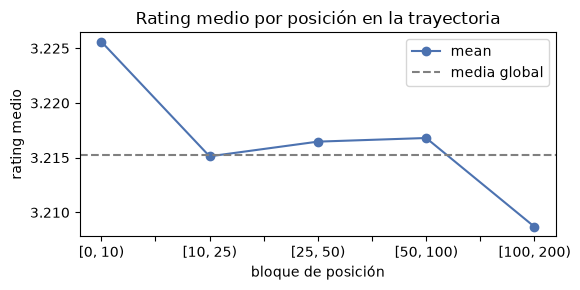

In [7]:
bloques = pd.cut(df["pos"], [0, 10, 25, 50, 100, 200], right=False)
pos_stats = (
    df.assign(bloque=bloques)
      .groupby("bloque", observed=True)["rating"]
      .agg(["count", "mean", "std"])
)
display(pos_stats.round(3))

rho_pos = df[["pos", "rating"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman(posición, rating) = {rho_pos:.4f}")

fig, ax = plt.subplots(figsize=(6, 3))
pos_stats["mean"].plot(ax=ax, marker="o", color="#4c72b0")
ax.axhline(df["rating"].mean(), color="gray", ls="--", label="media global")
ax.set_xlabel("bloque de posición")
ax.set_ylabel("rating medio")
ax.set_title("Rating medio por posición en la trayectoria")
ax.legend()
plt.tight_layout()
plt.show()

### ¿Los ítems que más aparecen son los mejor valorados?

Si el logging es uniforme, la frecuencia de un ítem no dice nada sobre su calidad. Se correlacionan apariciones y rating medio por ítem.

Pearson(frecuencia, rating medio)  = -0.0420
Spearman(frecuencia, rating medio) = -0.0572


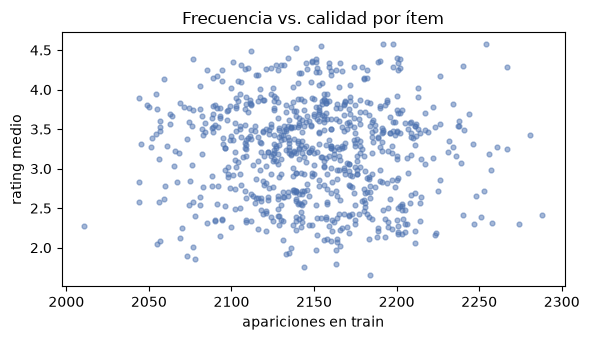

In [8]:
por_item = df.groupby("item")["rating"].agg(["count", "mean", "std"])
corr_pearson = por_item[["count", "mean"]].corr().loc["count", "mean"]
corr_spearman = por_item[["count", "mean"]].corr(method="spearman").loc["count", "mean"]
print(f"Pearson(frecuencia, rating medio)  = {corr_pearson:.4f}")
print(f"Spearman(frecuencia, rating medio) = {corr_spearman:.4f}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.scatter(por_item["count"], por_item["mean"], s=12, alpha=0.5, color="#4c72b0")
ax.set_xlabel("apariciones en train")
ax.set_ylabel("rating medio")
ax.set_title("Frecuencia vs. calidad por ítem")
plt.tight_layout()
plt.show()

### ¿Qué tan distintos son los grupos?

Los datos son sintéticos: cada grupo tiene una media `μ[g, i]` por ítem, y cada usuario es ese grupo más ruido. Dos usuarios del mismo grupo tienen los mismos gustos esperados, así que **conocer el grupo es conocer casi todo**. Se estima la media por grupo e ítem en train y se correlacionan los grupos entre sí.

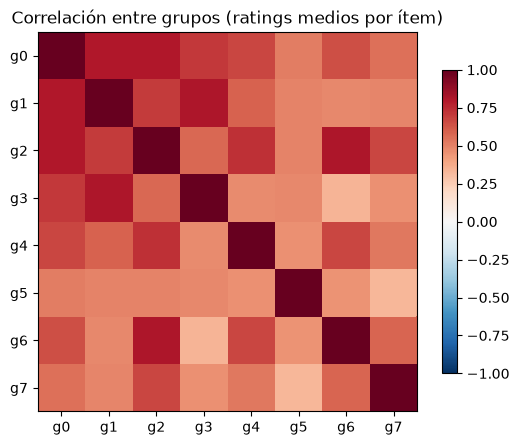

group,0,1,2,3,4,5,6,7
group,,,,,,,,
0,1.00,0.80,0.80,0.71,0.67,0.51,0.64,0.55
1,0.80,1.00,0.70,0.81,0.59,0.50,0.48,0.49
2,0.80,0.70,1.00,0.58,0.73,0.49,0.81,0.66
3,0.71,0.81,0.58,1.00,0.48,0.48,0.34,0.46
4,0.67,0.59,0.73,0.48,1.00,0.46,0.66,0.53
5,0.51,0.50,0.49,0.48,0.46,1.00,0.45,0.33
6,0.64,0.48,0.81,0.34,0.66,0.45,1.00,0.58
7,0.55,0.49,0.66,0.46,0.53,0.33,0.58,1.00


In [9]:
media_grupo_item = df.pivot_table(index="item", columns="group", values="rating", aggfunc="mean")
corr_grupos = media_grupo_item.corr()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(corr_grupos, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(8), [f"g{g}" for g in range(8)])
ax.set_yticks(range(8), [f"g{g}" for g in range(8)])
ax.set_title("Correlación entre grupos (ratings medios por ítem)")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

display(corr_grupos.round(2))

Algunos ítems ilustrativos (los mismos de la guía): el 144 gusta a todos, el 573 sólo al grupo 4 y el 3 divide aguas. También se buscan los ítems más específicos de grupo y se verifica que las medias observadas coincidan con las `μ` del generador.

In [10]:
ejemplos = [144, 3, 573]
display(media_grupo_item.loc[ejemplos].round(2))

dispersion_entre_grupos = media_grupo_item.std(axis=1)
mas_especificos = dispersion_entre_grupos.sort_values(ascending=False).head(10)
print("ítems con gustos más distintos entre grupos (mayor desvío entre medias):")
display(media_grupo_item.loc[mas_especificos.index].round(2).assign(desvio=mas_especificos.round(2)))

mu = pd.read_csv(paths["mu"], header=None).to_numpy()
observado = media_grupo_item.to_numpy().T
print(f"correlación entre medias observadas en train y μ del generador: {np.corrcoef(observado.ravel(), mu.ravel())[0, 1]:.4f}")

group,0,1,2,3,4,5,6,7
item,,,,,,,,
144,4.71,4.60,4.43,4.33,4.82,4.60,4.65,4.28
3,4.57,3.46,3.32,1.92,4.25,3.33,3.56,2.54
573,1.94,2.11,2.05,1.18,4.46,1.47,2.53,1.63


ítems con gustos más distintos entre grupos (mayor desvío entre medias):


group,0,1,2,3,4,5,6,7,desvio
item,,,,,,,,,
211,3.49,1.58,3.21,1.34,4.47,2.39,3.89,2.14,1.13
698,4.01,3.57,3.07,3.01,4.31,1.59,1.80,1.41,1.12
713,4.04,2.15,4.13,2.42,4.58,2.66,4.07,1.62,1.12
460,3.92,2.89,3.77,1.98,4.64,2.90,4.17,1.41,1.12
174,4.14,3.74,3.50,1.65,4.69,3.51,3.89,1.70,1.10
5,4.18,3.46,3.25,2.07,4.81,3.19,3.89,1.49,1.09
60,4.85,3.22,2.73,2.53,4.63,2.77,3.01,1.60,1.08
13,4.42,4.14,3.92,3.10,4.19,3.59,4.42,1.18,1.08
261,4.60,4.70,3.93,2.90,4.88,4.11,3.99,1.68,1.07


correlación entre medias observadas en train y μ del generador: 0.9974


## 2. Trayectorias, episodios y retorno pendiente

`make_episodes` corta cada trayectoria en tramos **consecutivos** de 20 pasos (el resto final se descarta). El retorno pendiente se calcula **dentro de cada episodio**:

```
R̂_t = r_t + r_{t+1} + … + r_{T−1}          R̂_{t+1} = R̂_t − r_t
```

Así su escala (entre 20 y 100) coincide con la de una sesión evaluada. La distribución de `R̂_0` define el soporte de retornos que después se usa para el *return conditioning* del DT.

episodios: 73,827 de 20 pasos
R̂_0: min 26 | p50 65 | max 97
cuantiles de R̂_0 (p10, p25, p50, p75, p90, p99): [46. 57. 65. 73. 81. 89.]


,t,ítem,rating,R̂_t
0,0,472,4.0,76.0
1,1,97,3.0,72.0
2,2,122,4.0,69.0
3,3,654,3.0,65.0
4,4,709,5.0,62.0
5,5,467,4.0,57.0
6,6,574,2.0,53.0
7,7,544,1.0,51.0


¿R̂_{t+1} = R̂_t − r_t en todo el episodio? True


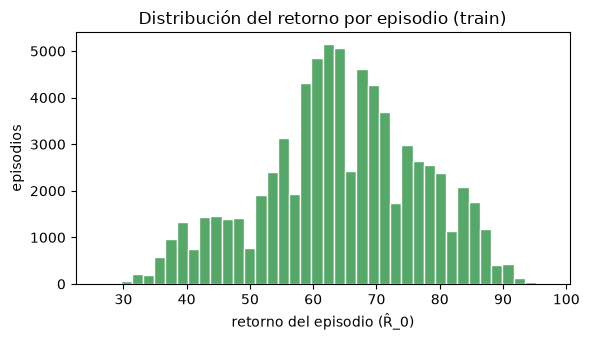

In [11]:
from protocolo.datos import make_episodes

L = 20
ep = make_episodes(train, length=L)
rtg = ep.returns_to_go()

print(f"episodios: {ep.items.shape[0]:,} de {ep.items.shape[1]} pasos")
print(f"R̂_0: min {rtg[:, 0].min():.0f} | p50 {np.median(rtg[:, 0]):.0f} | max {rtg[:, 0].max():.0f}")
print(f"cuantiles de R̂_0 (p10, p25, p50, p75, p90, p99): {np.percentile(rtg[:, 0], [10, 25, 50, 75, 90, 99]).round(1)}")

i = 0
tabla = pd.DataFrame({
    "t": np.arange(L),
    "ítem": ep.items[i],
    "rating": ep.ratings[i],
    "R̂_t": rtg[i],
})
display(tabla.head(8))
print("¿R̂_{t+1} = R̂_t − r_t en todo el episodio?", bool(np.allclose(rtg[i, 1:], rtg[i, :-1] - ep.ratings[i, :-1])))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(rtg[:, 0], bins=40, color="#55a868", edgecolor="white")
ax.set_xlabel("retorno del episodio (R̂_0)")
ax.set_ylabel("episodios")
ax.set_title("Distribución del retorno por episodio (train)")
plt.tight_layout()
plt.show()

## Conclusiones de la exploración

- **La política de registro es uniforme:** el rating medio no cambia con la posición (Spearman = −0,003) y la frecuencia de un ítem no se correlaciona con su calidad (Pearson = −0,04; Spearman = −0,06). Las trayectorias no contienen ni preferencias secuenciales ni "calidad revelada por popularidad".
- **El rating depende sólo de (grupo, ítem) más ruido:** no hay efectos de orden ni de historia. El valor de la secuencia sólo puede venir de identificar el grupo o de ajustar las preferencias con los ratings observados durante la sesión.
- **Los grupos son distintos, pero no opuestos:** todas las correlaciones entre pares de grupos son positivas (0,33 – 0,81), así que comparten gustos generales; aun así hay ítems muy específicos (por ejemplo, el 573 sólo le gusta al grupo 4). Saber el grupo es la señal más informativa, por eso `group_mean` y `group_posterior` son baselines fuertes.
- **Implicancias para las baselines:** `item_mean` es fuerte porque ordena por rating medio por ítem, una señal real de calidad; `popularity` debe rendir como `random` con logs uniformes; una política que no supere a `item_mean` no demuestra personalización, aunque su pérdida baje.
- **Implicancias para los modelos:** el DT condicionado por retorno imita los tramos de retorno alto; IQL estima ventajas y extrae π dentro del soporte. Ambos necesitan manejar el grupo oculto (token "desconocido") y adaptarse con el feedback de la sesión (warm-up).
- **Train/test:** ratings enteros 1–5 en Netflix (el test de Goodreads es continuo); los usuarios de test tienen el catálogo completo y su orden no es temporal. Train (14.400), val (1.600) y test (1.600) no comparten usuarios.
- **Episodios:** 73.827 tramos de 20 pasos consecutivos; `R̂_0` va de 26 a 97 (p10–p99: 46, 57, 65, 73, 81, 89), la misma escala que una sesión evaluada. Esos cuantiles fijan el soporte para elegir los retornos pedidos en el *return conditioning*.
- **Uso de `groups/*.csv`:** las medias observadas en train coinciden con las `μ` del generador (correlación 0,997); sirven para analizar y verificar, nunca como entrada de una política.